# Insurance Charges Prediction with Linear Regression
Linear regression implemented from scratch in PyTorch (manual gradient descent).

Dataset: Medical Cost Personal Dataset (1338 samples, 6 features).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

In [3]:
df = pd.read_csv('data/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.shape

(1338, 7)

## 1. Exploratory Data Analysis

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [7]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [10]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [11]:
df = df.drop_duplicates()
df.shape

(1337, 7)

In [12]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(1337, 7)

In [13]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


### Visualization

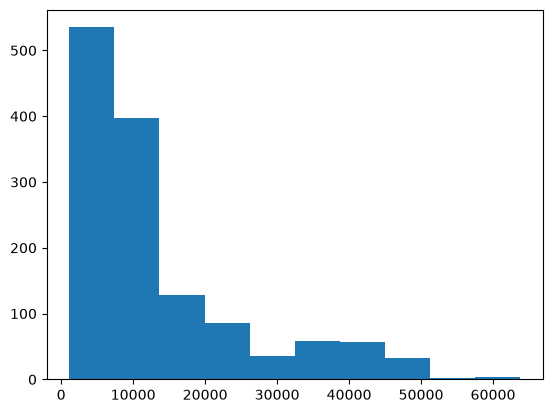

In [20]:
plt.hist(df['charges']);

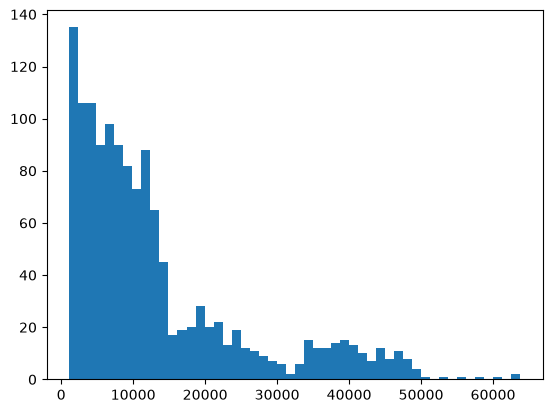

In [22]:
plt.hist(df['charges'], bins=50);

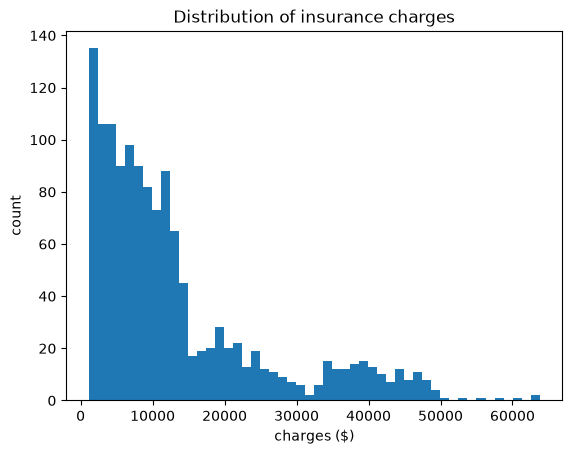

In [23]:
plt.hist(df['charges'], bins=50)
plt.xlabel('charges ($)')
plt.ylabel('count')
plt.title('Distribution of insurance charges');

In [24]:
df['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [25]:
df.groupby('smoker')['charges'].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

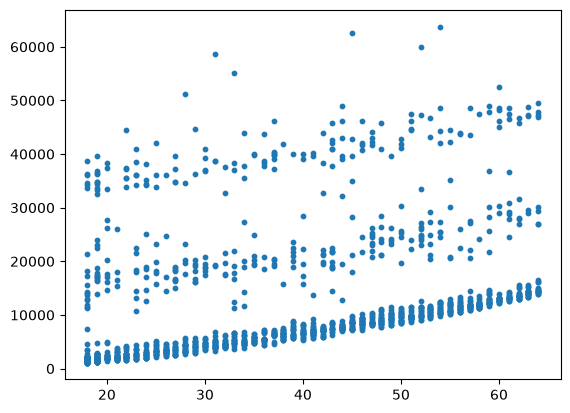

In [26]:
plt.scatter(df['age'], df['charges'], s=10);

In [28]:
df['smoker'].map({'yes': 'red', 'no': 'blue'})

0        red
1       blue
2       blue
3       blue
4       blue
        ... 
1332    blue
1333    blue
1334    blue
1335    blue
1336     red
Name: smoker, Length: 1337, dtype: str

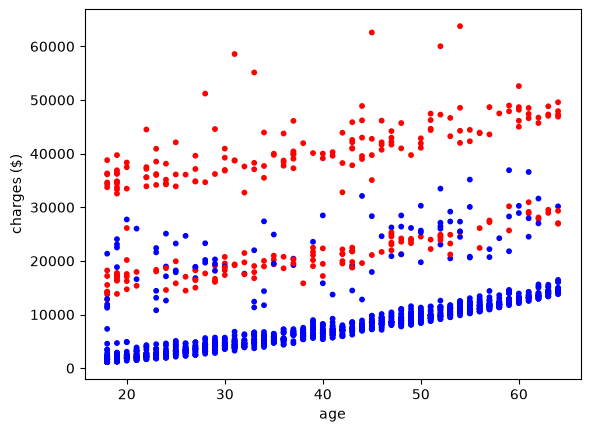

In [29]:
colors = df['smoker'].map({'yes': 'red', 'no': 'blue'})
plt.scatter(df['age'], df['charges'], c=colors, s=10)
plt.xlabel('age')
plt.ylabel('charges ($)');

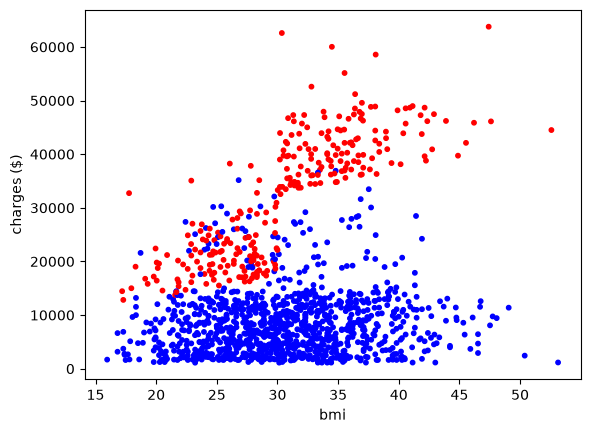

In [30]:
plt.scatter(df['bmi'], df['charges'], c=colors, s=10)
plt.xlabel('bmi')
plt.ylabel('charges ($)');

### Observations
- Smoking is the strongest factor: smokers pay about 4x more on average (≈32,000 USD vs ≈8,400 USD).
- Charges rise roughly linearly with age in every group.
- BMI barely matters for non-smokers, but smokers split into two groups around BMI 30: below 30 they pay about 20,000 USD, above 30 about 40,000 USD.
- So the effect of BMI depends on smoking (an interaction). A plain linear model gives each feature one fixed weight, so it cannot fully capture this pattern.
- A few non-smokers have high charges that none of the features explain, probably due to factors not in the dataset.

## 2. Preprocessing

In [31]:
pd.get_dummies(df)

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,True,False,False,True,False,False,False,True
1,18,33.770,1,1725.55230,False,True,True,False,False,False,True,False
2,28,33.000,3,4449.46200,False,True,True,False,False,False,True,False
3,33,22.705,0,21984.47061,False,True,True,False,False,True,False,False
4,32,28.880,0,3866.85520,False,True,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1332,50,30.970,3,10600.54830,False,True,True,False,False,True,False,False
1333,18,31.920,0,2205.98080,True,False,True,False,True,False,False,False
1334,18,36.850,0,1629.83350,True,False,True,False,False,False,True,False
1335,21,25.800,0,2007.94500,True,False,True,False,False,False,False,True


In [32]:
X_df = pd.get_dummies(df.drop(columns='charges'), drop_first=True)
X_df.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False


In [33]:
X_df = X_df.astype(float)
X_df.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,0.0,1.0,0.0,0.0,1.0
1,18.0,33.770,1.0,1.0,0.0,0.0,1.0,0.0
2,28.0,33.000,3.0,1.0,0.0,0.0,1.0,0.0
3,33.0,22.705,0.0,1.0,0.0,1.0,0.0,0.0
4,32.0,28.880,0.0,1.0,0.0,1.0,0.0,0.0


In [34]:
X = X_df.values
X.shape

(1337, 8)

In [36]:
y = df['charges'].values.reshape(-1, 1)
y.shape

(1337, 1)

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [38]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((1069, 8), (1069, 1), (268, 8), (268, 1))

In [39]:
X_train.min(axis=0), X_train.max(axis=0)

(array([18.  , 15.96,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ]),
 array([64.  , 53.13,  5.  ,  1.  ,  1.  ,  1.  ,  1.  ,  1.  ]))

In [40]:
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train)

In [41]:
X_train.mean(axis=0), X_train.std(axis=0)

(array([ 1.29560638e-16,  3.52986531e-15,  4.90201373e-17, -2.45931536e-16,
         2.60263695e-16, -2.38869313e-17, -5.02664120e-17, -1.42283026e-17]),
 array([1., 1., 1., 1., 1., 1., 1., 1.]))

In [42]:
X_test = x_scaler.transform(X_test)

In [43]:
X_test.mean(axis=0), X_test.std(axis=0)

(array([ 0.00849397,  0.10146346,  0.04823477, -0.0962037 ,  0.059213  ,
        -0.05351779,  0.04250826, -0.05561638]),
 array([1.01663105, 1.03596   , 1.04408196, 0.99816173, 1.04174221,
        0.96660781, 1.02108203, 0.9653821 ]))

In [44]:
y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train)
y_test = y_scaler.transform(y_test)

In [45]:
y_train[:5], y_scaler.inverse_transform(y_train[:5])

(array([[-0.90881619],
        [-0.83328687],
        [ 1.74700229],
        [ 0.03206437],
        [-0.28325331]]),
 array([[ 2396.0959 ],
        [ 3279.86855],
        [33471.97189],
        [13405.3903 ],
        [ 9715.841  ]]))

In [46]:
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

(torch.Size([1069, 8]),
 torch.Size([1069, 1]),
 torch.Size([268, 8]),
 torch.Size([268, 1]))

## 3. Model

With 8 features, element-wise `x * theta1` gives shape (1069, 8). Each feature needs its own weight and the results must be summed, so we use matrix multiplication: (1069, 8) @ (8, 1) → (1069, 1).

In [49]:
theta0 = torch.randn(1)
theta1 = torch.randn(1)

y_hat = X_train * theta1 + theta0
y_hat.shape

torch.Size([1069, 8])

In [50]:
theta0 = torch.randn(1)
w = torch.randn(8, 1)

y_hat = X_train @ w + theta0
y_hat.shape

torch.Size([1069, 1])

In [51]:
manual = (X_train[0] * w[:, 0]).sum() + theta0
manual, y_hat[0]

(tensor([-2.3069]), tensor([-2.3069]))

In [52]:
def linear_regression(x, theta0, w):
    y_hat = x @ w + theta0
    return y_hat

In [53]:
x_test_point = torch.ones(1, 8)
linear_regression(x_test_point, torch.tensor([3.0]), torch.full((8, 1), 2.0))

tensor([[19.]])

## 4. Loss

In [54]:
y_hat = linear_regression(X_train, theta0, w)
(y_hat - y_train).shape

torch.Size([1069, 1])

In [55]:
def mse(y_hat, y):
    return torch.mean((y_hat - y) ** 2)

loss = mse(y_hat, y_train)
loss

tensor(12.9218)

In [56]:
mse(torch.zeros_like(y_train), y_train)

tensor(1.)

## 5. Gradient Descent

In [57]:
error = y_hat - y_train
grad_w_age = 2 * torch.mean(X_train[:, 0:1] * error)
grad_w_age

tensor(-2.1933)

In [58]:
grad_w = 2 * (X_train.T @ error) / len(X_train)
grad_w.shape, grad_w[0]

(torch.Size([8, 1]), tensor([-2.1933]))

In [59]:
def calc_gradient(x, y, y_hat):
    error = y_hat - y
    grad_theta0 = 2 * torch.mean(error)
    grad_w = 2 * (x.T @ error) / len(x)
    return grad_theta0, grad_w

def update(theta0, w, eta, grad_theta0, grad_w):
    theta0 -= eta * grad_theta0
    w -= eta * grad_w
    return theta0, w

In [60]:
y_hat = linear_regression(X_train, theta0, w)
print('loss before:', mse(y_hat, y_train))

grad_theta0, grad_w = calc_gradient(X_train, y_train, y_hat)
theta0, w = update(theta0, w, 0.1, grad_theta0, grad_w)

y_hat = linear_regression(X_train, theta0, w)
print('loss after:', mse(y_hat, y_train))

loss before: tensor(12.9218)
loss after: tensor(8.2005)


## 6. Training

In [61]:
torch.manual_seed(42)
theta0 = torch.randn(1)
w = torch.randn(8, 1)

eta = 0.1
N = 100
losses = []

In [62]:
for i in range(N):
    # model
    y_hat = linear_regression(X_train, theta0, w)
    # loss
    loss = mse(y_hat, y_train)
    losses.append(loss.item())
    # gradient
    grad_theta0, grad_w = calc_gradient(X_train, y_train, y_hat)
    # update
    theta0, w = update(theta0, w, eta, grad_theta0, grad_w)

    if i % 10 == 0:
        print(f'Iter: {i}/{N}, Loss: {loss:.4f}')

Iter: 0/100, Loss: 9.0457
Iter: 10/100, Loss: 0.4243
Iter: 20/100, Loss: 0.3000
Iter: 30/100, Loss: 0.2783
Iter: 40/100, Loss: 0.2724
Iter: 50/100, Loss: 0.2707
Iter: 60/100, Loss: 0.2703
Iter: 70/100, Loss: 0.2701
Iter: 80/100, Loss: 0.2701
Iter: 90/100, Loss: 0.2701


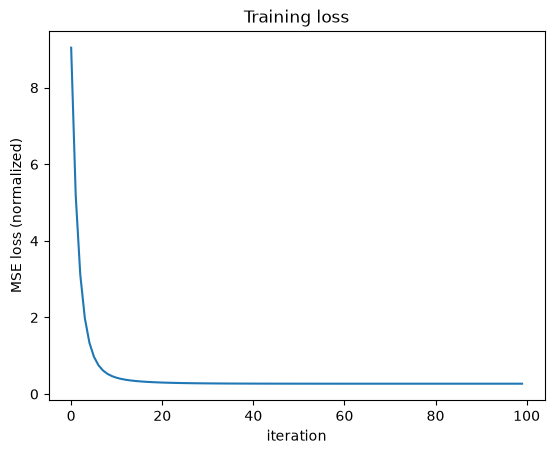

In [63]:
plt.plot(losses)
plt.xlabel('iteration')
plt.ylabel('MSE loss (normalized)')
plt.title('Training loss');

## 7. Evaluation

In [64]:
y_hat_test = linear_regression(X_test, theta0, w)
test_loss = mse(y_hat_test, y_test)
test_loss

tensor(0.2592)

In [65]:
y_pred_usd = y_scaler.inverse_transform(y_hat_test)
y_true_usd = y_scaler.inverse_transform(y_test)

In [66]:
np.hstack([y_true_usd[:10], y_pred_usd[:10]]).round(0)

array([[ 8689.,  8126.],
       [ 5709.,  5746.],
       [11437., 14372.],
       [38746., 31750.],
       [ 4463.,  8967.],
       [ 9305., 13155.],
       [38512., 30419.],
       [ 2150.,  1462.],
       [ 7346., 10639.],
       [10264., 11327.]])

In [67]:
mae = np.mean(np.abs(y_pred_usd - y_true_usd))
mae

np.float64(4177.101536947926)

In [68]:
ss_res = np.sum((y_true_usd - y_pred_usd) ** 2)
ss_tot = np.sum((y_true_usd - y_true_usd.mean()) ** 2)
r2 = 1 - ss_res / ss_tot
r2

np.float64(0.8068748636863519)

In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

sk_model = LinearRegression()
sk_model.fit(X_train.numpy(), y_train.numpy())

sk_pred = y_scaler.inverse_transform(sk_model.predict(X_test.numpy()))
r2_score(y_true_usd, sk_pred)

0.8069287084438079

In [70]:
w.T, sk_model.coef_

(tensor([[ 0.2969,  0.1645,  0.0544, -0.0043,  0.7892, -0.0134, -0.0306, -0.0232]]),
 array([[ 0.29680875,  0.16475688,  0.05439683, -0.00433719,  0.7891889 ,
         -0.01443838, -0.03177329, -0.02432355]], dtype=float32))

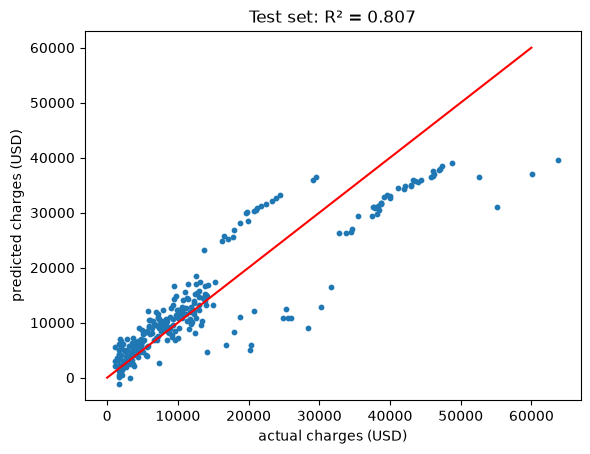

In [71]:
plt.scatter(y_true_usd, y_pred_usd, s=10)
plt.plot([0, 60000], [0, 60000], color='red')
plt.xlabel('actual charges (USD)')
plt.ylabel('predicted charges (USD)')
plt.title(f'Test set: R² = {r2:.3f}');

## 8. Improvement: smoker × BMI interaction

In [72]:
X_df2 = X_df.copy()
X_df2['smoker_bmi'] = X_df2['smoker_yes'] * X_df2['bmi']
X_df2[['bmi', 'smoker_yes', 'smoker_bmi']].head()

,bmi,smoker_yes,smoker_bmi
0,27.900,1.0,27.9
1,33.770,0.0,0.0
2,33.000,0.0,0.0
3,22.705,0.0,0.0
4,28.880,0.0,0.0


In [73]:
X2 = X_df2.values

X2_train, X2_test, _, _ = train_test_split(
    X2, y, test_size=0.2, random_state=42)

x2_scaler = StandardScaler()
X2_train = x2_scaler.fit_transform(X2_train)
X2_test = x2_scaler.transform(X2_test)

X2_train = torch.tensor(X2_train, dtype=torch.float32)
X2_test = torch.tensor(X2_test, dtype=torch.float32)

X2_train.shape, X2_test.shape

(torch.Size([1069, 9]), torch.Size([268, 9]))

In [75]:
torch.manual_seed(42)
theta0_2 = torch.randn(1)
w2 = torch.randn(9, 1)

eta = 0.1
N = 1000
losses2 = []

for i in range(N):
    y_hat = linear_regression(X2_train, theta0_2, w2)
    loss = mse(y_hat, y_train)
    losses2.append(loss.item())
    grad_theta0, grad_w = calc_gradient(X2_train, y_train, y_hat)
    theta0_2, w2 = update(theta0_2, w2, eta, grad_theta0, grad_w)

    if i % 100 == 0:
        print(f'Iter: {i}/{N}, Loss: {loss:.4f}')

Iter: 0/1000, Loss: 8.4047
Iter: 100/1000, Loss: 0.1909
Iter: 200/1000, Loss: 0.1824
Iter: 300/1000, Loss: 0.1786
Iter: 400/1000, Loss: 0.1768
Iter: 500/1000, Loss: 0.1760
Iter: 600/1000, Loss: 0.1756
Iter: 700/1000, Loss: 0.1754
Iter: 800/1000, Loss: 0.1753
Iter: 900/1000, Loss: 0.1753


In [76]:
y_hat_test2 = linear_regression(X2_test, theta0_2, w2)
y_pred_usd2 = y_scaler.inverse_transform(y_hat_test2)

mae2 = np.mean(np.abs(y_pred_usd2 - y_true_usd))
r2_2 = 1 - np.sum((y_true_usd - y_pred_usd2) ** 2) / np.sum((y_true_usd - y_true_usd.mean()) ** 2)

print(f'Model 1: R² = {r2:.3f}, MAE = {mae:.0f} USD')
print(f'Model 2: R² = {r2_2:.3f}, MAE = {mae2:.0f} USD')

Model 1: R² = 0.807, MAE = 4177 USD
Model 2: R² = 0.886, MAE = 2828 USD


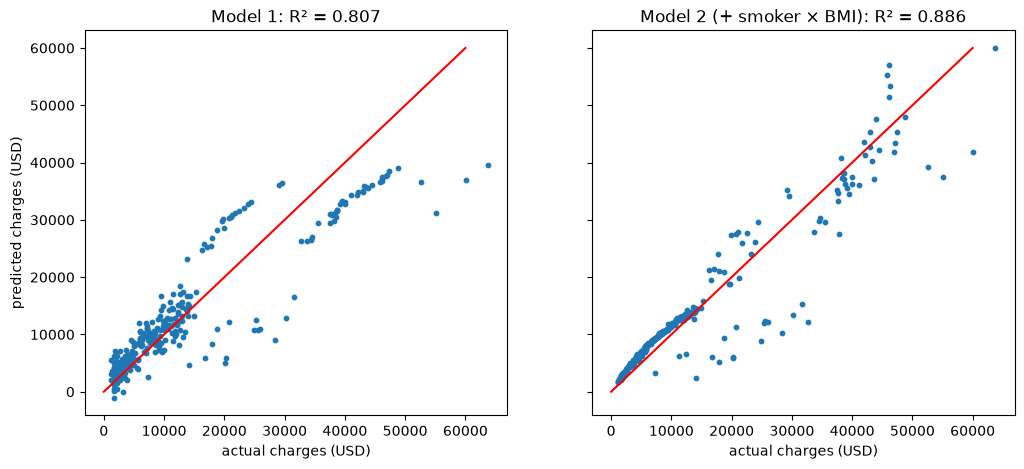

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(y_true_usd, y_pred_usd, s=10)
axes[0].set_title(f'Model 1: R² = {r2:.3f}')

axes[1].scatter(y_true_usd, y_pred_usd2, s=10)
axes[1].set_title(f'Model 2 (+ smoker × BMI): R² = {r2_2:.3f}')

for ax in axes:
    ax.plot([0, 60000], [0, 60000], color='red')
    ax.set_xlabel('actual charges (USD)')
axes[0].set_ylabel('predicted charges (USD)');